In [2]:
import numpy as np
import matplotlib.pyplot as plt
import h5py as h5
import sys
from tqdm import tqdm 

# set cosmology (for mdpl2)
from colossus.cosmology import cosmology
cosmo = cosmology.setCosmology('planck13')
a = 0.83760
redshift=1/a-1
H = cosmo.Hz(redshift)
h = cosmo.h

import halotools.sim_manager as sim_manager
import halotools.mock_observables as mock_observables

from compact.velocities.pw_moments import *
from compact.velocities.moments import *
from compact.catalog.accumulate import *
from compact.catalog.bin import *
from compact.streaming import *
from compact.tpcf import *
from compact.plot import *
from compact.model import *

from scipy.interpolate import UnivariateSpline

# reload project when changes are made
%load_ext autoreload
%autoreload 2

# plotting config
import matplotlib
matplotlib.rcParams.update({'text.usetex': True, 
                            'font.family': 'Computer Modern Roman'})
plt.rcParams['axes.labelsize'] = 20

import os
import warnings
warnings.filterwarnings('ignore')

import psutil
psutil.Process().nice(10)

from compact.velocities.pairhist import *

from scipy.optimize import curve_fit

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [3]:
# define grids

r_perp = np.linspace(5, 140, 135+1)
r_los = np.linspace(5, 140, 135+1)

r_p = 0.5*(r_perp[1:]+r_perp[:-1])
r_l = 0.5*(r_los[1:]+r_los[:-1])


r_p_2d, r_l_2d = np.meshgrid(r_p, r_l, indexing='ij')
r = np.sqrt(r_p_2d**2 + r_l_2d**2)

mu = r_p_2d/r 

x = r * ( 1 - mu ) 
x2 = r - r_p

In [4]:
cosmo = cosmology.setCosmology('planck18')

redshift=0.200
H = cosmo.Hz(redshift)
h = cosmo.h


box_length = 2000 #Mpc/h, AS box side length

m_p = 2e9 # h^-1 M_sun, particle mass

# massbins
log_edges = np.array([[12, 12.01], [12.5, 12.6], [13, 13.1], [13.5, 13.6], [14.0, 14.2], [14.4, 14.7]])
massbins = 10**log_edges

M_cens = (massbins[:, 0]*massbins[:, 1])**0.5

In [6]:
sims = [f'c000_ph{i:03d}' for i in range(12, 15)] # change as more come in 
REDSHIFT = 'z0.200'

sims

['c000_ph012', 'c000_ph013', 'c000_ph014']

In [ ]:
# load pairwise hists, fit



ST_pars_check = np.full((len(sims), len(M_cens), len(r_p), len(r_l), 3), np.nan) 
ST_errs_check = np.full(ST_pars_check.shape, np.nan) 
meas_sigv = np.full((len(sims), len(M_cens), len(r_p), len(r_l)), np.nan)

for si, sim in enumerate(sims):
    HALO_TMPL = ('/spiff/hengweichang/AbacusSummit_base/snapshots/'
                f'AbacusSummit_base_{sim}/halos/{REDSHIFT}/halo_combined.h5')
    SB_TMPL = ('/spiffball/cosweeney/simulations/AbacusSummit_base/halos/'
            f'AbacusSummit_base_{sim}/halos/{REDSHIFT}/SBp/')
    OUT_TMPL = ('/spiffball/cosweeney/simulations/AbacusSummit_base/halos/'
                f'AbacusSummit_base_{sim}/halos/{REDSHIFT}/data/pairhist_allbins.h5')
    LOG_TMPL = ('/spiffball/cosweeney/simulations/AbacusSummit_base/logs/'
                f'pairhist_{sim}.log')
    
    nus   = 6
    REBIN = 5        # 20 km/s fine bins -> 100 km/s, matching your linspace(...,51)
    N_MIN = 500      # replaces the isnan(hist) guard

    h = PairHist.load(OUT_TMPL)
    assert len(r_p) == h.n_R and len(r_l) == h.n_l

    cent_fine = h.v_centers                          # km/s, conv applied at accumulation
    dv        = (cent_fine[1] - cent_fine[0]) * REBIN
    cent      = cent_fine.reshape(-1, REBIN).mean(axis=1)

    #mean_vr_interp = mean_vr_r_interp

    for k in range(len(M_cens)):
        for j in range(len(r_p)):
            for i in range(len(r_l)):
                n = h.n[k, j, i]
                if n < N_MIN:
                    continue

                # n = h.n[k].astype(float)
                # n[n < N_MIN] = np.nan
                # mu = h.sum_v[k] / n
                # meas_sigv_check = np.sqrt(h.sum_v2[k] / n - mu**2)

                r_3d  = np.sqrt(r_p[j]**2 + r_l[i]**2)
                theta = np.arctan2(r_l[i], r_p[j])
                sin   = np.sin(theta)

                #peak = interps[k](r_3d) * sin #mean_vr_interp(r_3d)

                mu    = h.sum_v[k, j, i] / n
                width = np.sqrt(max(h.sum_v2[k, j, i] / n - mu**2, 0.0))

                counts   = h.counts[k, j, i].reshape(-1, REBIN).sum(axis=1)
                sel      = np.abs(cent - mu) <= 2500
                c_w, x_w = counts[sel], cent[sel]
                if c_w.sum() == 0:
                    continue

                hist = c_w / (c_w.sum() * dv)            # matches density=True over the window

                try:
                    p, c = curve_fit(lambda x, xi, omega, alpha: skewed_t_pdf(x, xi=xi, omega=omega, alpha=alpha, nu=nus),
                                    x_w, hist, p0=[mu, width, -0.1], method='lm', maxfev=5_000)
                except RuntimeError:
                    continue
                ST_pars_check[si, k, j, i] = p
                ST_errs_check[si, k, j, i] = np.sqrt(np.diag(c))
                meas_sigv[si, k, j, i] = width 


KeyboardInterrupt: 

In [34]:
sims

['c000_ph000', 'c000_ph001']

In [7]:
# parallel
from joblib import Parallel, delayed
from tqdm_joblib import tqdm_joblib
from tqdm import tqdm

nus   = 6
REBIN = 5        # 20 km/s fine bins -> 100 km/s
N_MIN = 500

ST_pars_check = np.full((len(sims), len(M_cens), len(r_p), len(r_l), 3), np.nan)
ST_errs_check = np.full(ST_pars_check.shape, np.nan)
meas_sigv     = np.full((len(sims), len(M_cens), len(r_p), len(r_l)), np.nan)


def fit_sim_k(si, k, n_k, sum_v_k, sum_v2_k, counts_k, cent, dv):
    out = {}
    for j in range(len(r_p)):
        for i in range(len(r_l)):
            n = n_k[j, i]
            if n < N_MIN:
                continue

            mu    = sum_v_k[j, i] / n
            width = np.sqrt(max(sum_v2_k[j, i] / n - mu**2, 0.0))

            counts   = counts_k[j, i].reshape(-1, REBIN).sum(axis=1)
            sel      = np.abs(cent - mu) <= 2500
            c_w, x_w = counts[sel], cent[sel]
            if c_w.sum() == 0:
                continue

            hist = c_w / (c_w.sum() * dv)

            try:
                p, c = curve_fit(lambda x, xi, omega, alpha: skewed_t_pdf(x, xi=xi, omega=omega, alpha=alpha, nu=nus),
                                 x_w, hist, p0=[mu, width, -0.1], method='lm', maxfev=5_000)
            except RuntimeError:
                continue
            out[(j, i)] = (p, np.sqrt(np.diag(c)), width)
    return si, k, out


for si, sim in enumerate(sims):
    OUT_TMPL = ('/spiffball/cosweeney/simulations/AbacusSummit_base/halos/'
                f'AbacusSummit_base_{sim}/halos/{REDSHIFT}/data/pairhist_allbins.h5')

    h = PairHist.load(OUT_TMPL)
    assert len(r_p) == h.n_R and len(r_l) == h.n_l

    cent_fine = h.v_centers
    dv        = (cent_fine[1] - cent_fine[0]) * REBIN
    cent      = cent_fine.reshape(-1, REBIN).mean(axis=1)

    with tqdm_joblib(tqdm(total=len(M_cens), desc=f"Fitting skew-T {sim}")):
        results = Parallel(n_jobs=-1)(
            delayed(fit_sim_k)(si, k, h.n[k], h.sum_v[k], h.sum_v2[k], h.counts[k], cent, dv)
            for k in range(len(M_cens))
        )

    for si_, k, out in results:
        for (j, i), (p, err, width) in out.items():
            ST_pars_check[si_, k, j, i] = p
            ST_errs_check[si_, k, j, i] = err
            meas_sigv[si_, k, j, i]     = width

    del h

Fitting skew-T c000_ph012:   0%|          | 0/6 [00:00<?, ?it/s]

  0%|          | 0/6 [00:00<?, ?it/s]

  0%|          | 0/6 [00:00<?, ?it/s]

Fitting skew-T c000_ph014:   0%|          | 0/6 [00:00<?, ?it/s]

  0%|          | 0/6 [00:00<?, ?it/s]

Fitting skew-T c000_ph013:   0%|          | 0/6 [06:09<?, ?it/s]


In [8]:
# save, allowing for new data to be appended later
save_path = '/spiffball/cosweeney/simulations/AbacusSummit_base/data/pdf_fits.h5'
arrays = {'ST_pars': ST_pars_check, 'ST_errs': ST_errs_check, 'meas_sigv': meas_sigv}

with h5.File(save_path, 'a') as hdf:
    for name, arr in arrays.items():
        if name in hdf:
            d = hdf[name]
            n = d.shape[0]
            d.resize(n + arr.shape[0], axis=0)
            d[n:] = arr
        else:
            hdf.create_dataset(name, data=arr,
                               maxshape=(None,) + arr.shape[1:],
                               chunks=True)

    old = list(hdf.attrs.get('sims', []))
    hdf.attrs['sims'] = np.array(old + list(sims), dtype=h5.string_dtype())

# with h5.File(save_path, 'a') as hdf:
#     for i, sim in enumerate(sims):
#         g = hdf.require_group(sim)
#         for name, arr in arrays.items():
#             if name in g:
#                 del g[name]          
#             g.create_dataset(name, data=arr[i])

In [5]:
save_path = '/spiffball/cosweeney/simulations/AbacusSummit_base/data/pdf_fits.h5'

sims = [f'c000_ph{i:03d}' for i in range(0, 15)]  # change as more come in
REDSHIFT = 'z0.200'

with h5.File(save_path, 'r') as hdf:
    ST_pars   = hdf['ST_pars'][:]
    ST_errs   = hdf['ST_errs'][:]
    meas_sigv = hdf['meas_sigv'][:]
    sims = [s.decode() if isinstance(s, bytes) else s for s in hdf.attrs['sims']]

In [6]:
# measure radial velocity profiles 

from scipy.interpolate import InterpolatedUnivariateSpline

def vr_profile(h, k, r_edges=None, r_max_trust=None):
    """Pair-weighted <v_r>(r) and sigma_vr(r) for mass bin k.

    Returns (r_eff, mean_vr, sigma_vr, n_pairs), all length len(r_edges)-1.
    r_eff is the pair-weighted mean radius in each bin, not the bin centre.
    Units follow the accumulator -- km/s if conv was applied at accumulation.
    """
    Rc = 0.5 * (h.R_edges[1:] + h.R_edges[:-1])
    lc = 0.5 * (h.rlos_edges[1:] + h.rlos_edges[:-1])
    r3 = np.sqrt(Rc[:, None]**2 + lc[None, :]**2).ravel()

    n = h.n[k].ravel().astype(float)
    s1 = h.sum_vr[k].ravel()
    s2 = h.sum_vr2[k].ravel()

    if r_edges is None:
        # default: 2 Mpc/h bins out to the largest radius with full angular
        # coverage (beyond R_edges[-1] only the cylinder corners contribute)
        top = r_max_trust if r_max_trust is not None else h.R_edges[-1]
        r_edges = np.arange(0.0, top + 2.0, 2.0)

    nb_bins = len(r_edges) - 1
    idx = np.searchsorted(r_edges, r3, side='right') - 1
    ok = (idx >= 0) & (idx < nb_bins) & (n > 0)

    def acc(w):
        return np.bincount(idx[ok], weights=w[ok], minlength=nb_bins)

    N = acc(n)
    r_eff = np.where(N > 0, acc(n * r3) / np.where(N > 0, N, 1), np.nan)
    mu = np.where(N > 0, acc(s1) / np.where(N > 0, N, 1), np.nan)
    m2 = np.where(N > 0, acc(s2) / np.where(N > 0, N, 1), np.nan)
    sd = np.sqrt(np.maximum(m2 - mu**2, 0.0))
    return r_eff, mu, sd, N.astype(np.int64)


def make_vr_interp(h, k, r_edges=None, r_max_trust=None, n_min=1000, ext=3):
    """Spline interpolator for <v_r>(r), analogous to mean_vr_r_interp.

    ext=3 clamps to the end values outside the fitted range rather than
    extrapolating or returning NaN -- your r_3d reaches ~198 Mpc/h at the grid
    corners, and a spline let loose out there will do something wild.
    """
    r, mu, _, N = vr_profile(h, k, r_edges, r_max_trust)
    good = np.isfinite(mu) & (N >= n_min)
    if good.sum() < 4:
        raise ValueError(f'mass bin {k}: only {good.sum()} usable radial bins')
    return InterpolatedUnivariateSpline(r[good], mu[good], k=3, ext=ext)

In [7]:
interps_sims = []
for sim in sims:
    OUT_TMPL = ('/spiffball/cosweeney/simulations/AbacusSummit_base/halos/'
                f'AbacusSummit_base_{sim}/halos/{REDSHIFT}/data/pairhist_allbins.h5')
    
    h = PairHist.load(OUT_TMPL)
    interps = {k: make_vr_interp(h, k) for k in range(6)}
    interps_sims.append(interps)

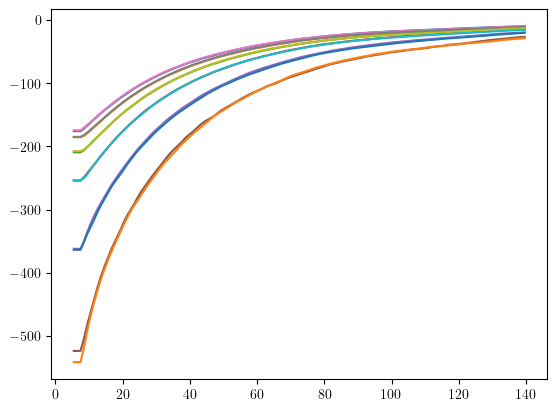

In [37]:
for sim in range(len(sims)):
    for k in range(len(M_cens)):
        plt.plot(r_p, interps_sims[sim][k](r_p))

In [8]:
def sigma_mod(x, sigma0, A_rho, sigma_rho):
    return np.sqrt(2 * sigma0**2 * (1 - A_rho * np.exp(-x / sigma_rho)))

def delta_mod(x, A_delta, sigma_delta):
    return A_delta * x / (sigma_delta + x)

In [12]:
# compute 1-D isotropic halo velocity dispersion for halos in sims. How different from one another, MDPL2?

# non-linear Pk instead 
import camb
from camb import model

camb_params = [cosmo.H0, cosmo.Ombh2, cosmo.Omh2 - cosmo.Ombh2, cosmo.ns]

def get_sigma0_nl(params, redshift, kmax=10.0, npoints=500):

    pars = camb.set_params(H0=params[0], ombh2=params[1], omch2=params[2], ns=params[3])
    pars.set_matter_power(redshifts=[redshift], kmax=10.0) 
    pars.NonLinear = model.NonLinear_both

    results = camb.get_results(pars)
    kh_nl, z_nl, pk_nl = results.get_matter_power_spectrum(
        minkh=1e-4, maxkh=5.0, npoints=500
    )
    pk_nl = pk_nl[0] 

    h = params[0] / 100.0

    Om0 = (params[1] + params[2]) / h**2
    Omz = Om0 * (1.0 + redshift)**3 / (params[0] / (100.0 * h))**2
    f = Omz**0.55 # growth rate

    a = 1/(1+redshift)
    conv = a * params[0] / h

    sigma0_nl_sq = (f * conv)**2 / (6 * np.pi**2) * simpson(pk_nl, kh_nl)
    sigma0_nl = np.sqrt(sigma0_nl_sq)

    return sigma0_nl

    
sigma = get_sigma0_nl(camb_params, 0.0)
print(sigma)


352.18191850987677


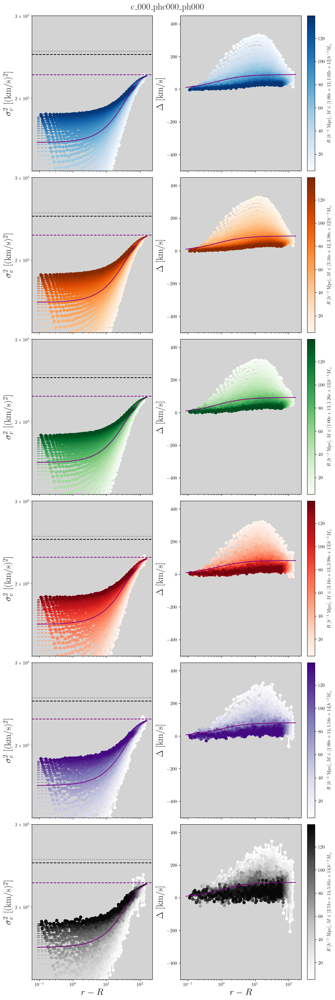

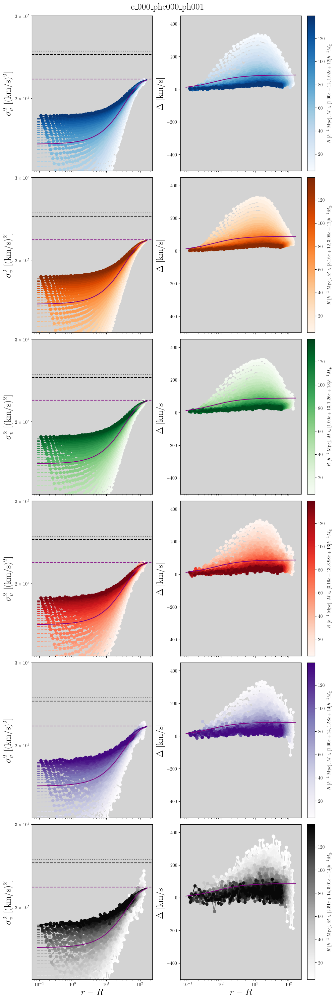

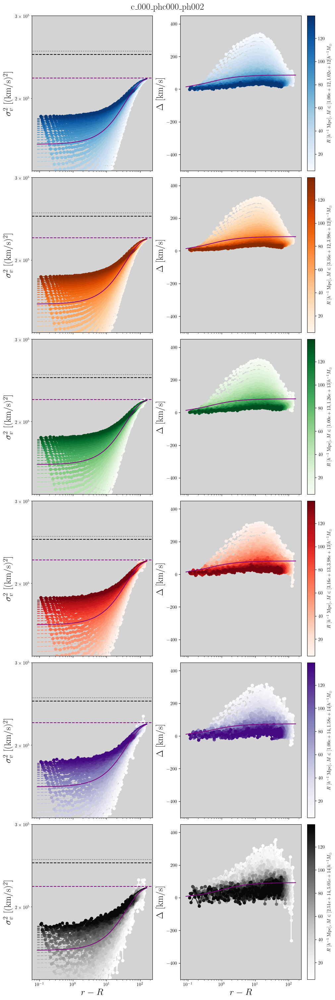

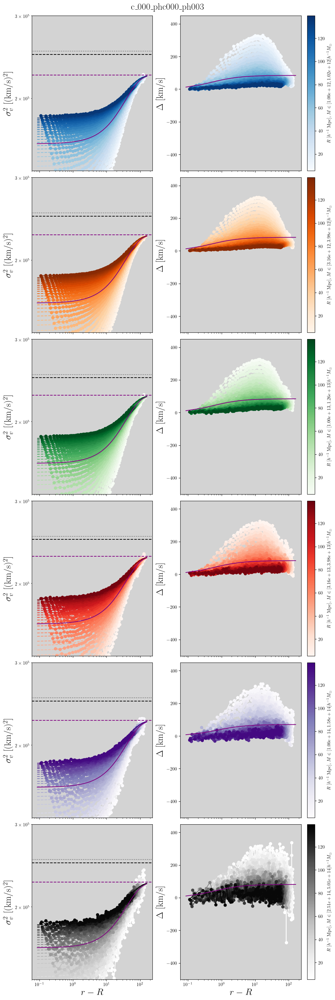

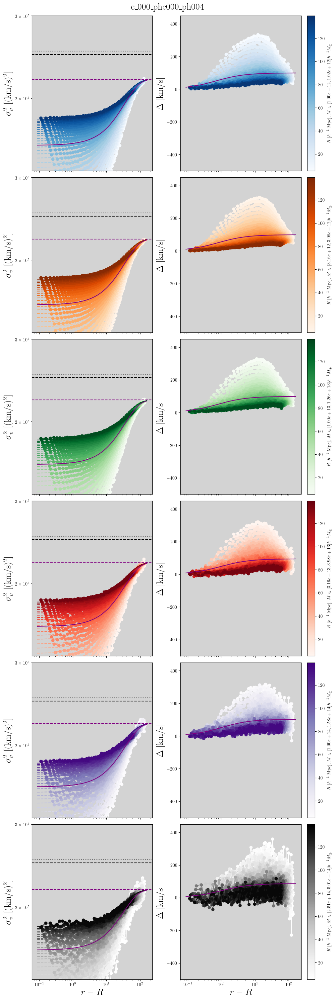

...

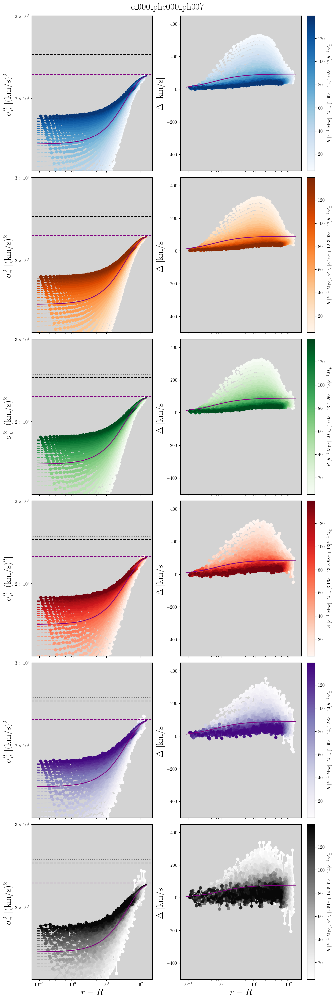

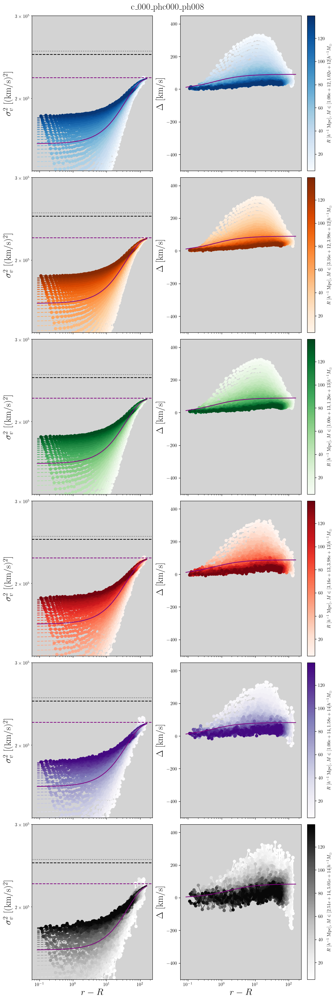

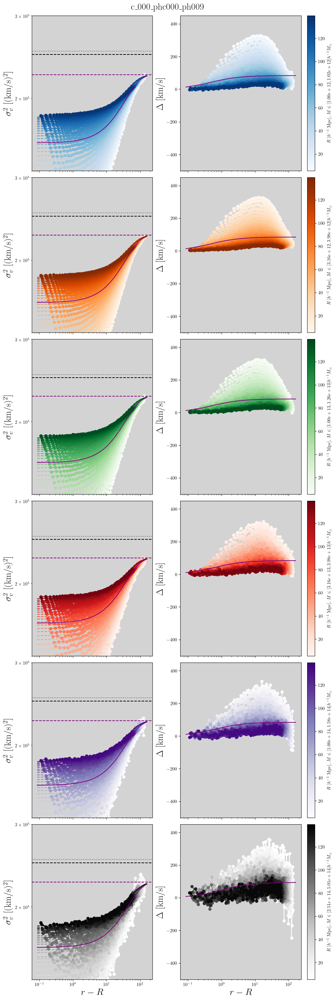

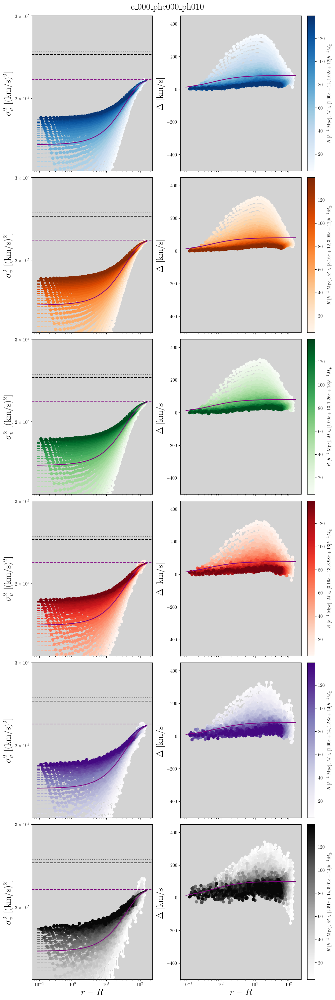

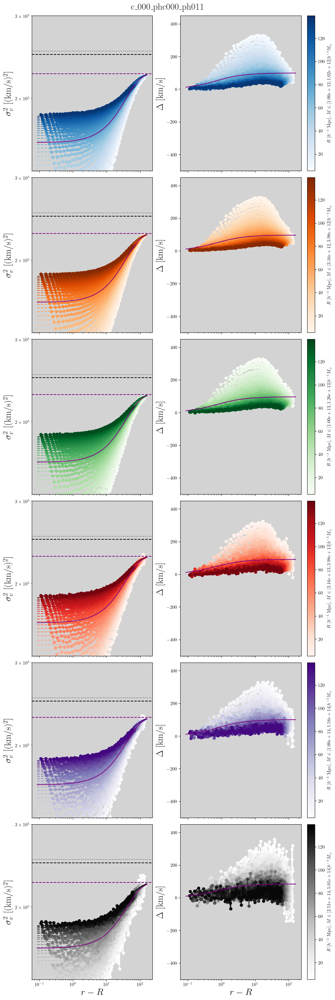

In [60]:
# fit compact functions to \sigma_v, \Delta

from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize


colormap_list = [plt.cm.Blues, plt.cm.Oranges, plt.cm.Greens, 
                 plt.cm.Reds, plt.cm.Purples, plt.cm.Greys]

cmaps = [cmap(np.linspace(0, 1, len(r_p))) for cmap in colormap_list]


names = [r'$\sigma_v^2$ [(km/s)$^2$]', r'$\Delta$ [km/s]']

sig_opts = np.full((len(sims), len(M_cens), 3), np.nan)
sig_errs = np.full(sig_opts.shape, np.nan)

del_opts = np.full((len(sims), len(M_cens), 2), np.nan)
del_errs = np.full(del_opts.shape, np.nan)


skip = 5


A_rho_R = np.full((len(sims), len(M_cens), len(r_p)//skip), np.nan)
A_rho_R_err = np.full(A_rho_R.shape, np.nan)


sig_rho_fix = sig_opts[:, :, -1]


for si, sim in enumerate(sims):
    fig, ax = plt.subplots(len(M_cens), 2, figsize=(10, 5*len(M_cens)), layout='constrained', sharex=True)

    fig.suptitle(rf"c_000_ph{sim}", fontsize=20)

    for k in range(len(M_cens)):

        mean_vr_interp = interps_sims[si][k]

        Delta = ST_pars_check[si, k, :, :, 0] - mean_vr_interp(r) * r_l / r
        com_inputs = [meas_sigv[si, k]**2, Delta]

        smask = np.isfinite(meas_sigv[si, k].flatten()) & (meas_sigv[si, k].flatten() > 0.1)
        dmask = np.isfinite(Delta.flatten()) & (Delta.flatten() > -1000)

        # fit models to each input 

        popt_sig, sig_cov = curve_fit(lambda x, sig, A, s: sigma_mod(x, sig, A, s), x.flatten()[smask], (meas_sigv[si, k]).flatten()[smask], p0=[sigma, 0.3, 10], maxfev=5_000, absolute_sigma=False)
        popt_del, del_cov = curve_fit(delta_mod, x.flatten()[dmask], Delta.flatten()[dmask], p0=[100, 1], maxfev=5_000, absolute_sigma=False)

        sig_opts[si, k] = popt_sig
        sig_errs[si, k] = np.sqrt(np.diag(sig_cov))
        del_opts[si, k] = popt_del 
        del_errs[si, k] = np.sqrt(np.diag(del_cov))


        xs = np.linspace(x.min()*(1-0.2), x.max()*(1+0.2), 1000)

        for j in range(0, len(r_p), skip):
            for i in range(2):

                y = com_inputs[i][j, :]
                
                if i == 0:
                    mask = y > 0.1

                    if j == 0:
                        popt, pcov = curve_fit(lambda x, A: sigma_mod(x, sig_opts[si, k, 0], A, popt_sig[-1]), x2[:, j], meas_sigv[si, k, j, :], p0=popt_sig[1], maxfev=5_000, absolute_sigma=True)
                        A_rho_R[si, k, j//skip] = popt #, sig_rho_fix
                        A_rho_R_err[si, k, j//skip] = np.sqrt(pcov) #[0, 0]

                        ax[k, i].plot(xs, sigma_mod(xs, sig_opts[si, k, 0], popt, popt_sig[-1] )**2, c=cmaps[k][j], ls='--')

                    else:
                        popt, pcov = curve_fit(lambda x, A: sigma_mod(x, sig_opts[si, k, 0], A, popt_sig[-1]), x2[:, j], meas_sigv[si, k, j, :], p0=popt_sig[1], maxfev=5_000, absolute_sigma=True)

                        A_rho_R[si, k, j//skip] = popt
                        A_rho_R_err[si, k, j//skip] = np.sqrt(pcov)

                        ax[k, i].plot(xs, sigma_mod(xs, sig_opts[si, k, 0], popt, popt_sig[-1] )**2, c=cmaps[k][j], ls='--')

                if i == 1:
                    mask = y > -1000

                ax[k, i].plot(x2[:, j][mask], y[mask], marker='o', c=cmaps[k][j])

                ax[k, i].set_facecolor('lightgray')
                
                ax[k, i].set_ylabel(names[i], fontsize=20)
                
                ax[k, i].set_xscale('log')
                
        norm = Normalize(vmin=min(r_p), vmax=max(r_p))
        sm = ScalarMappable(norm=norm, cmap=colormap_list[k])
        sm.set_array([])  # dummy array
        cbar = fig.colorbar(sm, ax=ax[k, -1])
        cbar.set_label(rf"$R \ [h^{{-1}}$ Mpc], $M\in[{massbins[k, 0]:.2e}, {massbins[k, 1]:.2e}] h^{{-1}} M_\odot $", fontsize=10)

        ax[k, 0].plot(xs, sigma_mod(xs, *popt_sig )**2, c='purple') #*popt_sig
        ax[k, 0].set_ylim((140_000, 300_000))
        ax[k, 0].set_xscale('log')
        ax[k, 0].axhline(2*(sigma)**2, c='k', ls='--')
        ax[k, 0].axhline(2*(popt_sig[0])**2, c='purple', ls='--')
        ax[k, 0].axhline(2*(355)**2, c='k', ls=':', alpha=0.5)
        ax[k, 0].set_yscale('log')

        ax[-1, 0].set_xlabel(r'$r-R$', fontsize=20)
        ax[-1, 1].set_xlabel(r'$r-R$', fontsize=20)

        ax[k, 1].plot(xs, delta_mod(xs, *popt_del), c='purple')
        ax[k, 1].set_ylim((-500, 450))

In [15]:
sims = [f'c000_ph{i:03d}' for i in range(0, 15)] # change as more come in 
REDSHIFT = 'z0.200'

sims

['c000_ph000',
 'c000_ph001',
 'c000_ph002',
 'c000_ph003',
 'c000_ph004',
 'c000_ph005',
 'c000_ph006',
 'c000_ph007',
 'c000_ph008',
 'c000_ph009',
 'c000_ph010',
 'c000_ph011',
 'c000_ph012',
 'c000_ph013',
 'c000_ph014']

phc000_ph000 k=0: sigma0=330.1+-0.0  A_piv=0.289+-0.000  b=103.08+-0.20  sigma_rho=29.23+-0.07  | corr(A,b)=+0.64 corr(b,s_rho)=+0.63 corr(s0,A)=+0.66  A(R_min)=0.554
phc000_ph000 k=1: sigma0=331.3+-0.0  A_piv=0.287+-0.000  b=104.38+-0.20  sigma_rho=29.50+-0.07  | corr(A,b)=+0.64 corr(b,s_rho)=+0.64 corr(s0,A)=+0.66  A(R_min)=0.545
phc000_ph000 k=2: sigma0=332.1+-0.0  A_piv=0.285+-0.000  b=105.01+-0.20  sigma_rho=29.65+-0.07  | corr(A,b)=+0.64 corr(b,s_rho)=+0.64 corr(s0,A)=+0.67  A(R_min)=0.539
phc000_ph000 k=3: sigma0=332.6+-0.0  A_piv=0.286+-0.000  b=109.12+-0.21  sigma_rho=31.41+-0.08  | corr(A,b)=+0.66 corr(b,s_rho)=+0.66 corr(s0,A)=+0.70  A(R_min)=0.529
phc000_ph000 k=4: sigma0=333.0+-0.1  A_piv=0.285+-0.000  b=113.98+-0.24  sigma_rho=33.52+-0.09  | corr(A,b)=+0.68 corr(b,s_rho)=+0.69 corr(s0,A)=+0.74  A(R_min)=0.514
phc000_ph000 k=5: sigma0=332.6+-0.1  A_piv=0.282+-0.000  b=122.00+-0.36  sigma_rho=34.09+-0.12  | corr(A,b)=+0.66 corr(b,s_rho)=+0.69 corr(s0,A)=+0.75  A(R_min)=0.48

phc000_ph010 k=3: sigma0=328.7+-0.0  A_piv=0.272+-0.000  b=103.26+-0.20  sigma_rho=29.14+-0.07  | corr(A,b)=+0.64 corr(b,s_rho)=+0.63 corr(s0,A)=+0.66  A(R_min)=0.520
phc000_ph010 k=4: sigma0=328.4+-0.1  A_piv=0.275+-0.000  b=111.71+-0.25  sigma_rho=31.61+-0.09  | corr(A,b)=+0.65 corr(b,s_rho)=+0.66 corr(s0,A)=+0.71  A(R_min)=0.501
phc000_ph010 k=5: sigma0=326.8+-0.1  A_piv=0.270+-0.000  b=116.03+-0.36  sigma_rho=32.83+-0.12  | corr(A,b)=+0.66 corr(b,s_rho)=+0.68 corr(s0,A)=+0.73  A(R_min)=0.482
phc000_ph011 k=0: sigma0=331.4+-0.0  A_piv=0.294+-0.000  b=104.95+-0.19  sigma_rho=30.04+-0.07  | corr(A,b)=+0.65 corr(b,s_rho)=+0.65 corr(s0,A)=+0.67  A(R_min)=0.557
phc000_ph011 k=1: sigma0=332.9+-0.0  A_piv=0.294+-0.000  b=106.29+-0.19  sigma_rho=30.47+-0.07  | corr(A,b)=+0.65 corr(b,s_rho)=+0.65 corr(s0,A)=+0.68  A(R_min)=0.552
phc000_ph011 k=2: sigma0=333.7+-0.0  A_piv=0.290+-0.000  b=107.03+-0.19  sigma_rho=30.66+-0.07  | corr(A,b)=+0.65 corr(b,s_rho)=+0.65 corr(s0,A)=+0.69  A(R_min)=0.54

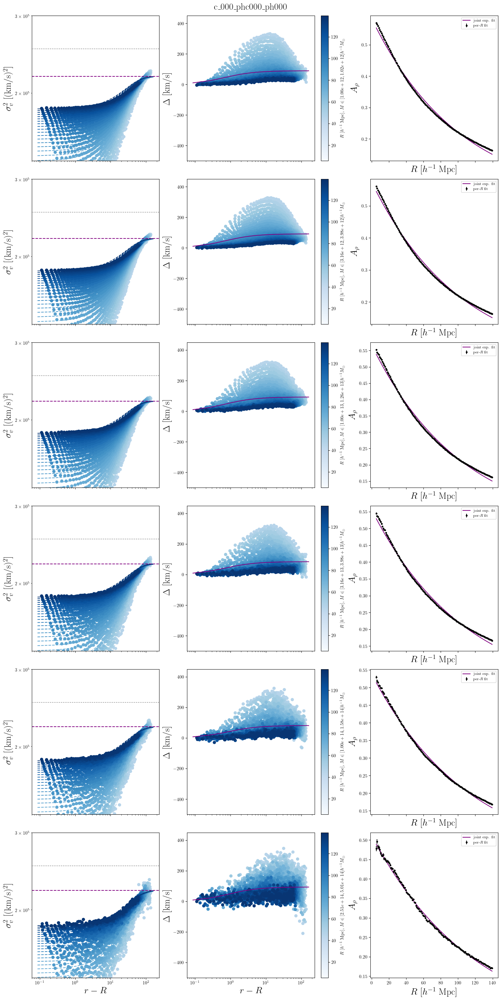

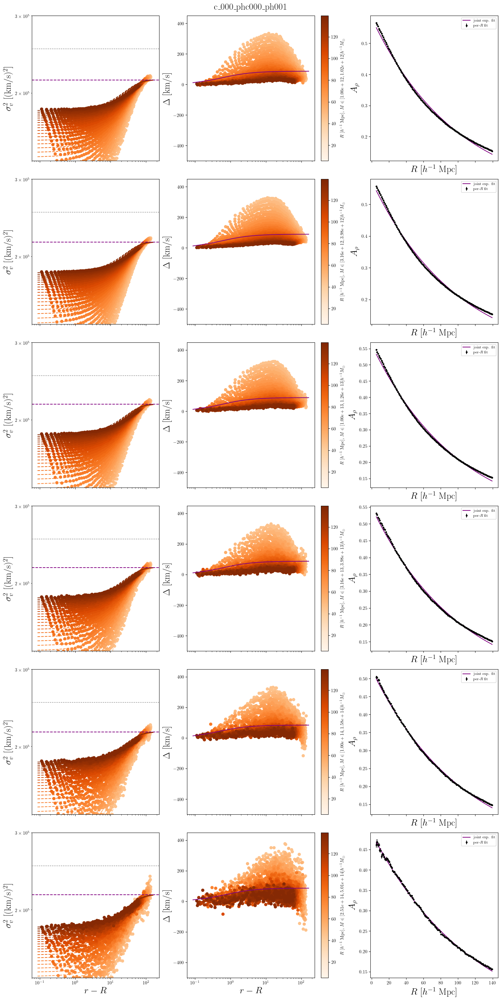

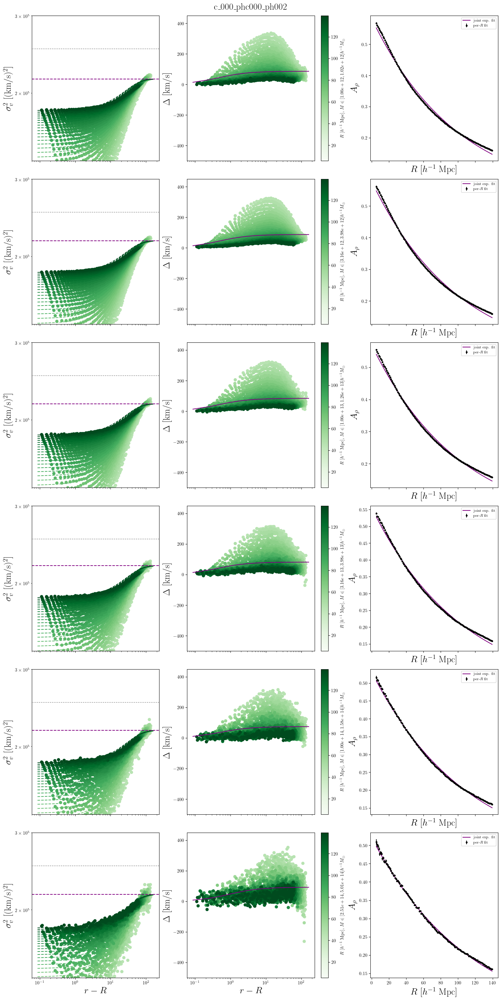

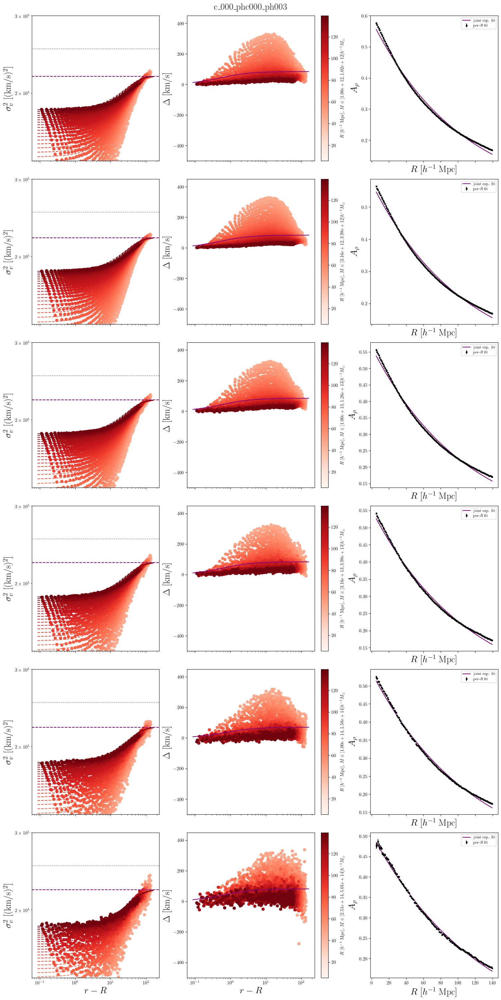

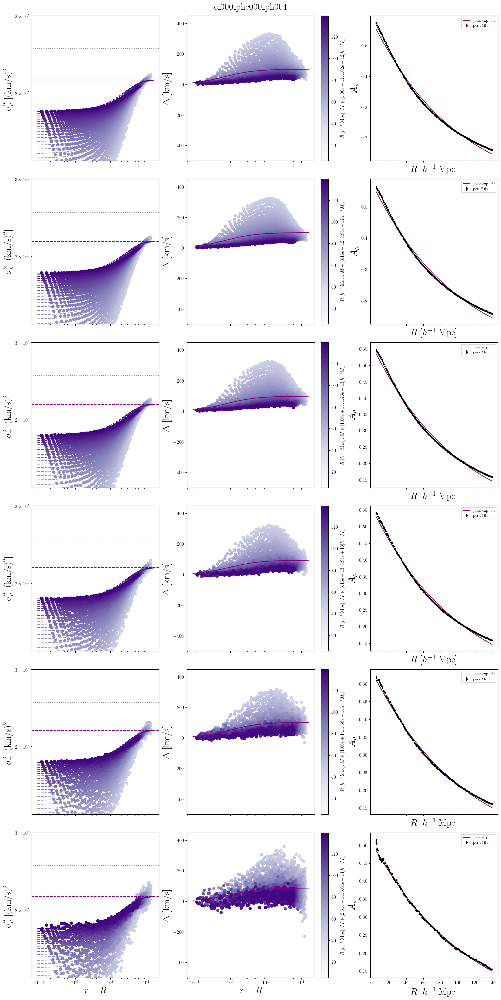

...

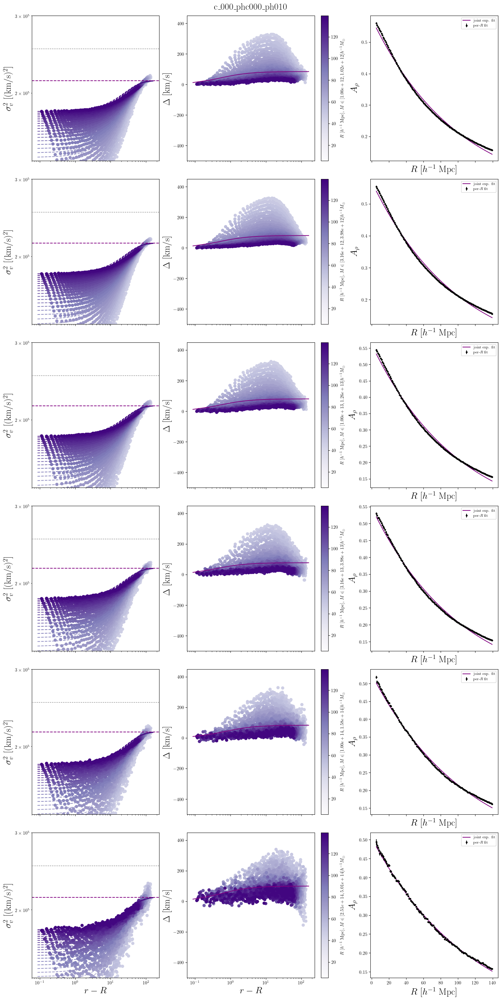

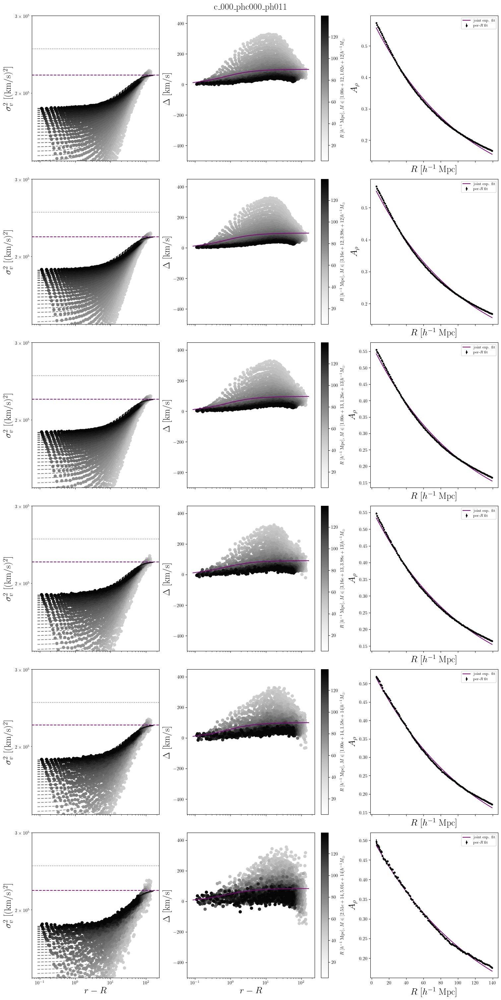

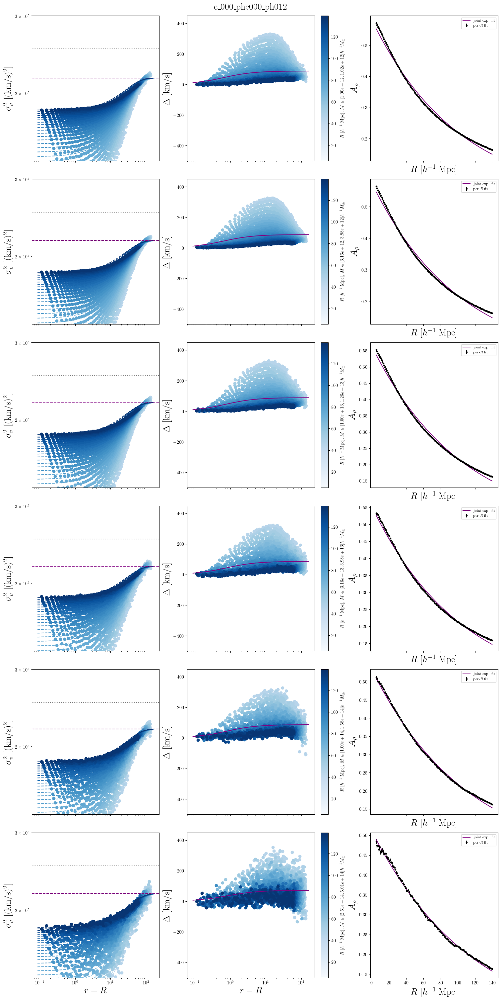

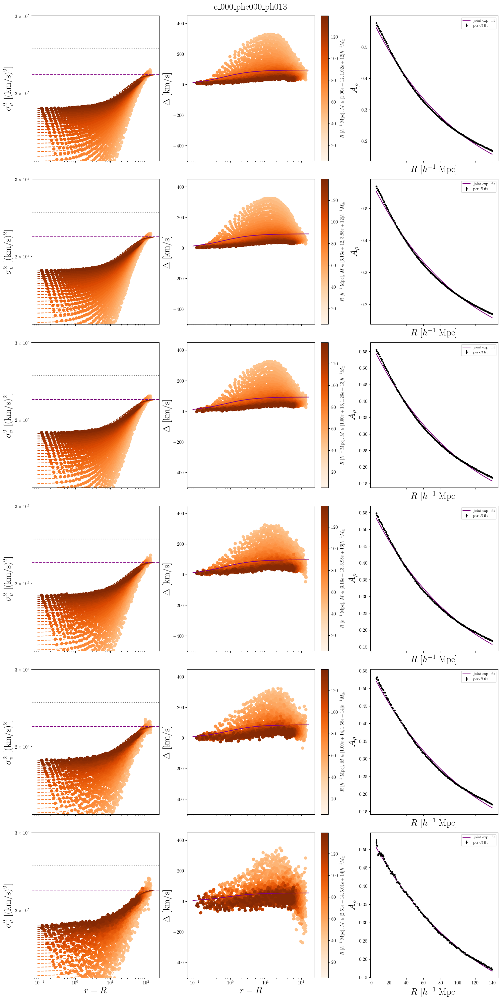

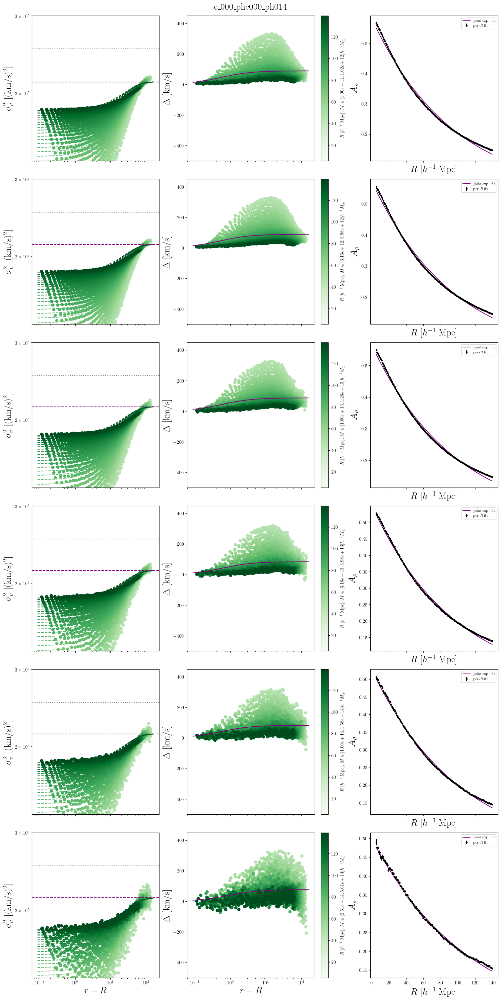

In [10]:
"""
Compact-model calibration: joint fit of

    sigma_v(x, R) = sqrt( 2 sigma0^2 [ 1 - A_rho(R) exp(-x/sigma_rho) ] )
    A_rho(R)      = A_piv exp( -(R - R_piv)/b )
    Delta(x)      = A_delta x / (sigma_delta + x)

with x = r - R.

Array-shape assumptions (state these before running):
  x, meas_sigv[si,k], Delta   ->  (n_R, n_rlos)
  r_p                         ->  (n_R,)
  x2 in the old code          ==  x.T   (so old x2[:, j]  ->  x[j])
"""

from scipy.optimize import curve_fit
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

SIG_FLOOR = 0.1      # km/s, drop unfit/empty cells
DEL_FLOOR = -1000.0  # km/s


# ---------------------------------------------------------------- models
def sigma_mod(x, sigma0, A_rho, sigma_rho):
    arg = 2.0 * sigma0**2 * (1.0 - A_rho * np.exp(-x / sigma_rho))
    return np.sqrt(np.clip(arg, 1e-8, None))


def A_rho_mod(R, A_piv, b, R_piv):
    return A_piv * np.exp(-(R - R_piv) / b)


def sigma_mod_2d(coords, sigma0, A_piv, b, sigma_rho, R_piv):
    x, R = coords
    return sigma_mod(x, sigma0, A_rho_mod(R, A_piv, b, R_piv), sigma_rho)


def delta_mod(x, A_delta, sigma_delta):
    return A_delta * x / (sigma_delta + x)


# ---------------------------------------------------------------- fitting
def _seed(x, R, sig, R_piv):
    """Linearised seed. With y = 2 sigma0^2 - sigma_v^2,

        log y = log(2 sigma0^2 A_piv) - (R - R_piv)/b - x/sigma_rho

    is linear in (R, x), so an lstsq gives starting values for free."""
    sigma0 = sig.max() / np.sqrt(2.0) * 1.02
    y = 2.0 * sigma0**2 - sig**2
    m = y > 0
    G = np.column_stack([np.ones(m.sum()), -(R[m] - R_piv), -x[m]])
    c = np.linalg.lstsq(G, np.log(y[m]), rcond=None)[0]

    b = 1.0 / c[1] if c[1] > 0 else np.ptp(R) + 1.0
    sigma_rho = 1.0 / c[2] if c[2] > 0 else 10.0
    A_piv = np.clip(np.exp(c[0]) / (2.0 * sigma0**2), 1e-3, 0.99)
    return [sigma0, A_piv, b, sigma_rho]


def fit_sigma_joint(x, r_p, sig, R_piv=None):
    """Single fit for (sigma0, A_piv, b, sigma_rho) using every (R, x) cell."""
    R = np.broadcast_to(r_p[:, None], x.shape)
    m = np.isfinite(x) & np.isfinite(sig) & (sig > SIG_FLOOR)
    X, RR, S = x[m], R[m], sig[m]

    if R_piv is None:
        R_piv = np.median(RR)

    popt, pcov = curve_fit(
        lambda c, s0, Ap, b, sr: sigma_mod_2d(c, s0, Ap, b, sr, R_piv),
        (X, RR), S, p0=_seed(X, RR, S, R_piv),
        bounds=([0.0, 1e-4, 1e-3, 1e-3], [np.inf, 1.0, np.inf, np.inf]),
        maxfev=20_000,
    )
    perr = np.sqrt(np.diag(pcov))
    corr = pcov / np.outer(perr, perr)
    return popt, perr, corr, R_piv


def fit_A_per_R(x, sig, sigma0, sigma_rho):
    """Old per-R_perp fit, kept as a diagnostic: is A_rho(R) really exponential?"""
    A = np.full(x.shape[0], np.nan)
    Aerr = np.full(x.shape[0], np.nan)
    for j in range(x.shape[0]):
        m = np.isfinite(x[j]) & np.isfinite(sig[j]) & (sig[j] > SIG_FLOOR)
        if m.sum() < 3:
            continue
        p, c = curve_fit(lambda xx, a: sigma_mod(xx, sigma0, a, sigma_rho),
                         x[j][m], sig[j][m], p0=[0.3],
                         bounds=(1e-4, 1.0), maxfev=10_000)
        A[j], Aerr[j] = p[0], np.sqrt(c[0, 0])
    return A, Aerr


def fit_delta(x, D):
    m = np.isfinite(x) & np.isfinite(D) & (D > DEL_FLOOR)
    popt, pcov = curve_fit(delta_mod, x[m], D[m], p0=[100.0, 1.0], maxfev=10_000)
    return popt, np.sqrt(np.diag(pcov))


# ---------------------------------------------------------------- driver
colormap_list = [plt.cm.Blues, plt.cm.Oranges, plt.cm.Greens,
                 plt.cm.Reds, plt.cm.Purples, plt.cm.Greys]
names = [r'$\sigma_v^2$ [(km/s)$^2$]', r'$\Delta$ [km/s]']

n_sim, n_M, n_R = len(sims), len(M_cens), len(r_p)

sig_opts = np.full((n_sim, n_M, 4), np.nan)   # sigma0, A_piv, b, sigma_rho
sig_errs = np.full_like(sig_opts, np.nan) 
sig_corr = np.full((n_sim, n_M, 4, 4), np.nan)
R_pivs   = np.full((n_sim, n_M), np.nan)
del_opts = np.full((n_sim, n_M, 2), np.nan)
del_errs = np.full_like(del_opts, np.nan)
A_rho_R     = np.full((n_sim, n_M, n_R), np.nan)
A_rho_R_err = np.full_like(A_rho_R, np.nan)

skip = 5   # plotting stride only; the fits use every R bin
xs = np.linspace(x.min() * 0.8, x.max() * 1.2, 1000)

for si, sim in enumerate(sims):
    fig, ax = plt.subplots(n_M, 3, figsize=(15, 5 * n_M),
                           layout='constrained', sharex='col')
    fig.suptitle(rf"c_000_ph{sim}", fontsize=20)
    cmap_k = colormap_list[si % len(colormap_list)]

    for k in range(n_M):
        sig = meas_sigv[si, k]
        Delta = ST_pars[si, k, :, :, 0] - interps_sims[si][k](r) * r_l / r

        # --- fits -------------------------------------------------------
        popt, perr, corr, R_piv = fit_sigma_joint(x, r_p, sig)
        sig_opts[si, k], sig_errs[si, k], sig_corr[si, k] = popt, perr, corr
        R_pivs[si, k] = R_piv
        del_opts[si, k], del_errs[si, k] = fit_delta(x, Delta)

        A_rho_R[si, k], A_rho_R_err[si, k] = fit_A_per_R(x, sig, popt[0], popt[3])

        # --- panel 0: sigma_v^2 vs x, one curve per R -------------------
        colors = cmap_k(np.linspace(0.3, 1, n_R))
        for j in range(0, n_R, skip):
            m = sig[j] > SIG_FLOOR
            ax[k, 0].plot(x[j][m], sig[j][m]**2, 'o', c=colors[j])
            ax[k, 0].plot(xs, sigma_mod(xs, popt[0],
                                        A_rho_mod(r_p[j], popt[1], popt[2], R_piv),
                                        popt[3])**2, c=colors[j], ls='--')
        ax[k, 0].axhline(2 * popt[0]**2, c='purple', ls='--')
        ax[k, 0].axhline(2 * 355.0**2, c='k', ls=':', alpha=0.5)
        ax[k, 0].set(xscale='log', yscale='log', ylim=(140_000, 300_000),
                     ylabel=names[0])

        # --- panel 1: Delta --------------------------------------------
        for j in range(0, n_R, skip):
            m = Delta[j] > DEL_FLOOR
            ax[k, 1].plot(x[j][m], Delta[j][m], 'o', c=colors[j])
        ax[k, 1].plot(xs, delta_mod(xs, *del_opts[si, k]), c='purple')
        ax[k, 1].set(xscale='log', ylim=(-500, 450), ylabel=names[1])

        # --- panel 2: A_rho(R), joint fit vs per-bin --------------------
        ax[k, 2].errorbar(r_p, A_rho_R[si, k], A_rho_R_err[si, k],
                          fmt='o', c='k', ms=3, label='per-$R$ fit')
        ax[k, 2].plot(r_p, A_rho_mod(r_p, popt[1], popt[2], R_piv),
                      c='purple', label='joint exp. fit')
        ax[k, 2].set(xlabel=r'$R\ [h^{-1}$ Mpc]', ylabel=r'$A_\rho$')
        ax[k, 2].legend(fontsize=8)

        sm = ScalarMappable(norm=Normalize(vmin=r_p.min(), vmax=r_p.max()), cmap=cmap_k)
        sm.set_array([])
        cbar = fig.colorbar(sm, ax=ax[k, 1])
        cbar.set_label(
            rf"$R\ [h^{{-1}}$ Mpc], $M\in[{massbins[k,0]:.2e}, {massbins[k,1]:.2e}]"
            rf" h^{{-1}} M_\odot$", fontsize=10)

        print(f"ph{sim} k={k}: sigma0={popt[0]:.1f}+-{perr[0]:.1f}  "
              f"A_piv={popt[1]:.3f}+-{perr[1]:.3f}  b={popt[2]:.2f}+-{perr[2]:.2f}  "
              f"sigma_rho={popt[3]:.2f}+-{perr[3]:.2f}  "
              f"| corr(A,b)={corr[1,2]:+.2f} corr(b,s_rho)={corr[2,3]:+.2f} "
              f"corr(s0,A)={corr[0,1]:+.2f}  A(R_min)={A_rho_mod(r_p.min(), *popt[1:3], R_piv):.3f}")

    for i in range(2):
        ax[-1, i].set_xlabel(r'$r-R$', fontsize=20)

In [22]:
np.mean(sig_corr[:, :, 2, 3])

np.float64(0.6495070209019718)

In [24]:
parameters.shape

(12, 6, 6)

In [30]:
fixed_parameters.shape

(5,)

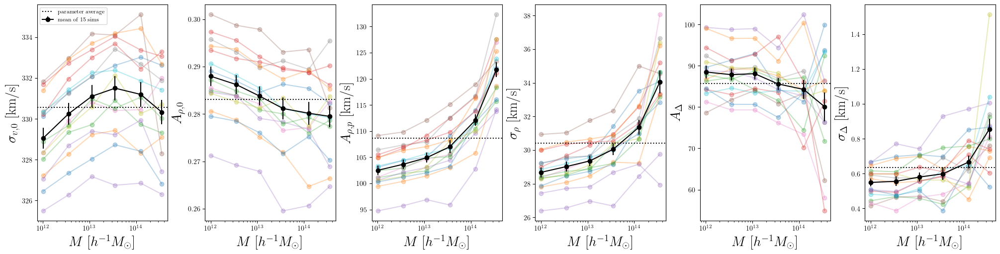

In [12]:
# plot pars as function of M for each sim

fig, ax = plt.subplots(1, 6, figsize=(20, 5), layout='constrained')

fixed_parameters = np.concatenate(([355], sig_pars, del_pars)) # form MDPL2
parameters = np.concatenate((sig_opts, del_opts), axis=-1)  # (n_sims, n_mass, n_params)

labels = [r"$\sigma_{v, 0}$ [km/s]", r"$A_{\rho, 0}$", r"$A_{\rho, p}$ [km/s]", r"$\sigma_\rho$ [km/s]", r"$A_\Delta$", r"$\sigma_\Delta$ [km/s]"]

n_sims = parameters.shape[0]

# leave-one-out jackknife across sims, vectorized
total = parameters.sum(axis=0)                        # (n_mass, n_params)
mean_vals = total / n_sims                             # (n_mass, n_params)
loo_means = (total - parameters) / (n_sims - 1)        # (n_sims, n_mass, n_params)
jack_err = np.sqrt((n_sims - 1) / n_sims * np.sum((loo_means - mean_vals) ** 2, axis=0))

for i, label in enumerate(labels):
    for si, sim in enumerate(sims):
        ax[i].plot(M_cens, parameters[si, :, i], marker='o', alpha=0.3) #label=f"{sim}"
    ax[i].errorbar(M_cens, mean_vals[:, i], yerr=jack_err[:, i], marker='o', color='k', label=f'mean of {len(sims)} sims')
    ax[i].axhline(np.mean(mean_vals[:, i]), c='k', ls=':', label='parameter average')
    #ax[i].axhline(fixed_parameters[i], c='k', ls='--', label='MDPL2 fit')
    ax[i].set_ylabel(label)
    ax[i].set_xlabel(r'$M\ [h^{-1} M_\odot]$')
    ax[i].set_xscale('log')

#ax[0].axhline(sigma, c='k', ls='-.', label=f'CAMB prediction')
ax[0].legend(fontsize=8)

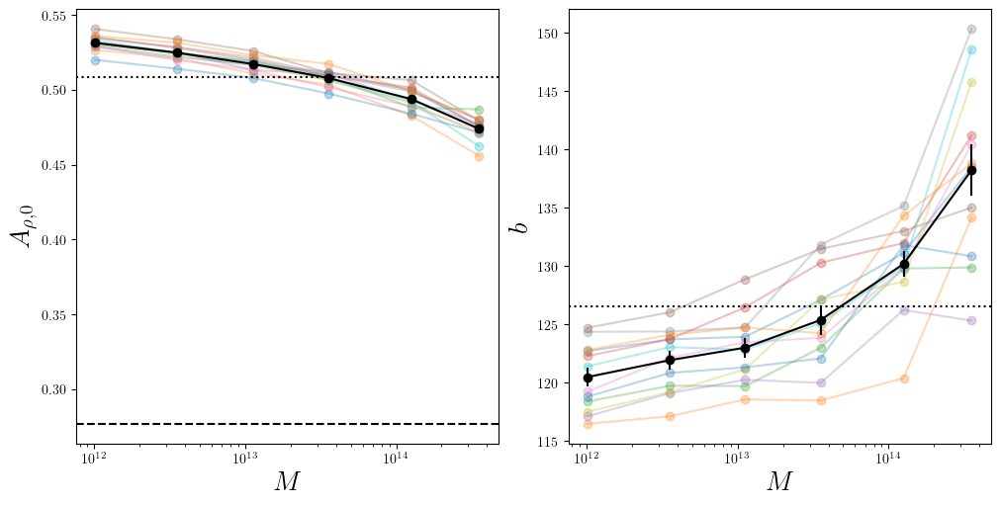

In [68]:

def exp_model(r_p, A_0, b):
    return A_0 * np.exp(-r_p/b)

n_sims, n_mass, n_rp = A_rho_R.shape

A_0_fit = np.zeros((n_sims, n_mass))
b_fit = np.zeros((n_sims, n_mass))

for si in range(n_sims):
    for mi in range(n_mass):
        y = A_rho_R[si, mi]
        p0 = [y[0], 1/0.1]
        popt, _ = curve_fit(exp_model, r_p[::5], y, p0=p0)
        A_0_fit[si, mi], b_fit[si, mi] = popt

# jackknife (leave-one-sim-out) over sims, vectorized, same as before
def jackknife_mean_err(x):
    # x: (n_sims, n_mass)
    total = x.sum(axis=0)
    mean_vals = total / n_sims
    loo_means = (total - x) / (n_sims - 1)
    err = np.sqrt((n_sims - 1) / n_sims * np.sum((loo_means - mean_vals) ** 2, axis=0))
    return mean_vals, err

A_0_mean, A_0_err = jackknife_mean_err(A_0_fit)
b_mean, b_err = jackknife_mean_err(b_fit)

fig, ax = plt.subplots(1, 2, figsize=(10, 5), layout='constrained')

R_pars = [A_0_fit, b_fit]

for i in range(2):
    for si, sim in enumerate(sims):
        ax[i].plot(M_cens, R_pars[i][si, :], marker='o', label=f"{sim}", alpha=0.3)
            
ax[0].errorbar(M_cens, A_0_mean, yerr=A_0_err, marker='o', c='k')
ax[0].axhline(np.mean(A_0_mean), c='k', ls=':')
ax[0].axhline(np.mean(mean_vals[:, 1]), c='k', ls='--')
ax[0].set_ylabel(r"$A_{\rho, 0}$")
ax[0].set_xlabel(r'$M$')
ax[0].set_xscale('log')

ax[1].errorbar(M_cens, b_mean, yerr=b_err, marker='o', c='k')
ax[1].axhline(np.mean(b_mean), c='k', ls=':')
ax[1].set_ylabel(r"$b$")
ax[1].set_xlabel(r'$M$')
ax[1].set_xscale('log')

In [46]:
b_mean.shape

(6,)

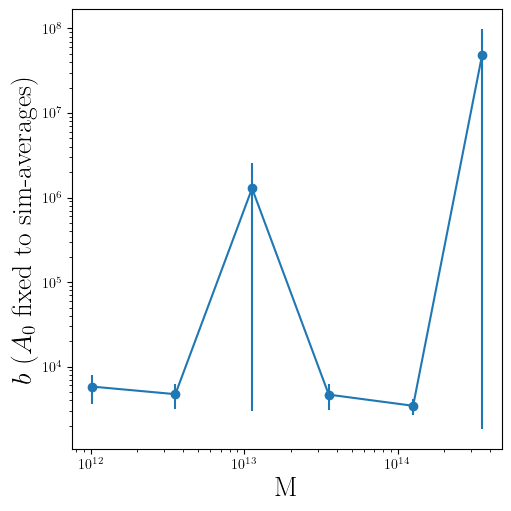

In [23]:
A_rho_M_mean = mean_vals[:, 1]  # from the first snippet, (n_mass,), A_rho averaged over sims

def exp_model_fixed_A0(r_p, b, A_0):
    return A_0 * np.exp(-r_p/b)

b_fit_fixedA0 = np.zeros((n_sims, n_mass))

for si in range(n_sims):
    for mi in range(n_mass):
        y = A_rho_R[si, mi]
        A_0 = A_rho_M_mean[mi]
        popt, _ = curve_fit(lambda r_p, b: exp_model_fixed_A0(r_p, b, A_0), r_p[::5], y, p0=[1/0.1])
        b_fit_fixedA0[si, mi] = popt[0]

b_fixedA0_mean, b_fixedA0_err = jackknife_mean_err(b_fit_fixedA0)

fig, ax = plt.subplots(figsize=(5, 5), layout='constrained')
ax.errorbar(M_cens, b_fixedA0_mean, yerr=b_fixedA0_err, marker='o')
ax.set_ylabel(r"$b$ ($A_0$ fixed to sim-averages)")
ax.set_xlabel(r'M')
ax.set_xscale('log')
ax.set_yscale('log')

In [37]:
A_rho_R.shape

(12, 6, 27)

In [38]:
A_rho_R_mean, A_rho_err = jackknife_mean_err(A_rho_R)


In [47]:
A_0[mi]

IndexError: invalid index to scalar variable.

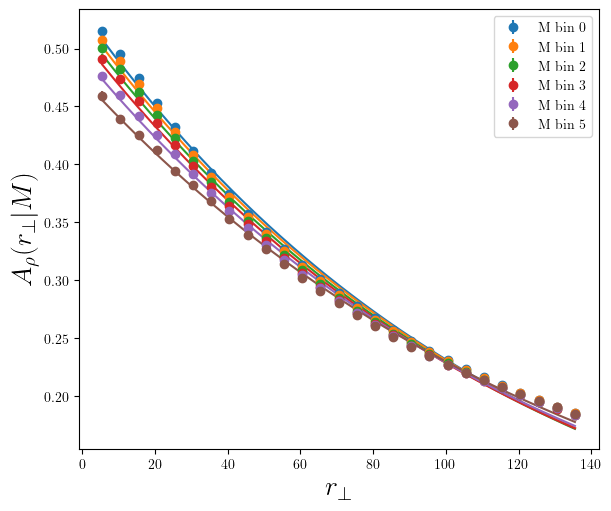

In [65]:
A_rho_R_mean, A_rho_R_err = jackknife_mean_err(A_rho_R)
#A_rho_R.mean(axis=0)  # (n_mass, n_rp), averaged over sims

fig, ax = plt.subplots(figsize=(6, 5), layout='constrained')

r_p_grid = np.linspace(r_p[::skip].min(), r_p[::skip].max(), 200)

for mi in range(n_mass): 
#    ax.plot(r_p[::skip], A_rho_R_mean[mi] / A_rho_M_mean[mi], marker='o', label=f"M bin {mi}")
    ax.errorbar(r_p[::skip], A_rho_R_mean[mi], A_rho_R_err[mi], fmt='o', c=f'C{mi}', label=f"M bin {mi}")
    ax.plot(r_p_grid, A_0_mean[mi]*np.exp(-r_p_grid/b_mean[mi]), c=f'C{mi}')

    # ratio = np.exp(-r_p_grid/b_fixedA0_mean[mi])
    # ax.plot(r_p_grid, ratio, label=f"M bin {mi}", c=f'C{mi}')

ax.set_ylabel(r"$A_\rho(r_\perp|M)$")
ax.set_xlabel(r'$r_\perp$')
ax.legend()

In [ ]:
A_rho_R_mean = A_rho_R.mean(axis=0)  # (n_mass, n_rp), averaged over sims

fig, ax = plt.subplots(figsize=(6, 5), layout='constrained')

r_p_grid = np.linspace(r_p[::skip].min(), r_p[::skip].max(), 200)

for mi in range(n_mass):
#    ax.plot(r_p[::skip], A_rho_R_mean[mi] / A_rho_M_mean[mi], marker='o', label=f"M bin {mi}")
    ax.plot(r_p[::skip], A_rho_R_mean[mi] , marker='o', label=f"M bin {mi}")

    # ratio = np.exp(-r_p_grid/b_fixedA0_mean[mi])
    # ax.plot(r_p_grid, ratio, label=f"M bin {mi}", c=f'C{mi}')

ax.set_ylabel(r"$A_\rho(r_\perp|M)$")
ax.set_xlabel(r'$r_\perp$')
ax.legend()